# CalculiX validation: the solver behind PrePoMax, driven from Python

**Units: SI** (N, m, Pa). CalculiX has no units of its own, so any consistent set works. Inputs are in N, m and Pa, and results are printed in mm and MPa for reading. **Signs:** tensile stress is positive. The cantilever's tip load acts in $-z$, and tip deflections are reported as positive downward magnitudes.

CalculiX is an open-source (GPL) finite element solver. [PrePoMax](https://prepomax.fs.um.si/) is a free Windows GUI around it and bundles a build of the solver (`Solver/ccx_dynamic.exe`, CalculiX 2.22 in v3.0.0). This notebook never opens PrePoMax. It writes the `.inp` file, runs `ccx` with `subprocess`, and parses the text results.

Each check compares CalculiX with a closed form using `math.isclose` at a stated tolerance, and prints OK or FAIL. Checks 2 to 4 use the repository's shared benchmark: **2 m of 50 × 50 mm steel with a 1 kN tip load**, which deflects 25.600 mm by $PL^3/3EI$. Other packages in the README solve the same beam, so these results cross-check them too. The last cell prints a summary table and raises if any check fails.

| # | Check | Closed form | Why CalculiX rather than scikit-fem |
|---|---|---|---|
| 1a | Wide plate with a small hole, $K_t$ | Kirsch, $K_t = 3$ | quadratic plane-stress mesh from gmsh |
| 1b, 1c | Plate with a central hole, $d/w = 0.25$, $K_t$ | Howland's solution (curve fit); Shigley Fig. A-15-1 | same |
| 2 | 2 m cantilever, 3D solids (C3D10) | $PL^3/3EI$ plus shear term | real 3D elements |
| 3a, 3b | Same cantilever with beam elements (B32), then a short beam | $PL^3/3EI$ plus shear term | beam element library |
| 4 | Same bar as a fixed-free column, linear buckling | Shigley Eq. (4-43), $C = 1/4$ | buckling analysis (`*BUCKLE`) |

## Requirements

- Python packages: `pip install numpy pandas matplotlib gmsh`.
- **CalculiX itself is not a pip package and is not included here.** Get a solver binary from either [PrePoMax](https://prepomax.fs.um.si/) (Windows; unzip it and keep the whole `Solver` folder together, because the executable needs the MKL DLLs beside it) or [calculix.de](http://www.calculix.de/) / your Linux package manager (`ccx`).
- Tell the notebook where it is with **one** of: the `CCX_EXE` environment variable (full path to the executable), the `PREPOMAX_HOME` environment variable (the unzipped PrePoMax folder), or `ccx` on your `PATH`.
- To re-run it headless, **don't set `MPLBACKEND=Agg`**. Under Agg, `plt.show()` draws nothing, so the saved notebook loses its plots:

  ```bash
  jupyter nbconvert --to notebook --execute CalculiX_Validation_Checks.ipynb --inplace
  ```

References: Budynas and Nisbett, *Shigley's Mechanical Engineering Design*, 10th ed., Fig. A-15-1 in Table A-15 (printed p. 1034), Ex. 6-13, Eq. (4-43) and Table 4-2 (printed p. 197). Example and equation numbers follow that edition. Values read from a chart are marked as such.

In [1]:
import re, subprocess, tempfile, math, os, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import gmsh

def find_ccx():
    # CCX_EXE, then PREPOMAX_HOME/Solver, then the PATH. Raises with instructions if none works.
    tried = []
    if os.environ.get("CCX_EXE"):
        tried.append(Path(os.environ["CCX_EXE"]))
    if os.environ.get("PREPOMAX_HOME"):
        tried.append(Path(os.environ["PREPOMAX_HOME"]) / "Solver" / "ccx_dynamic.exe")
    tried += [Path(p) for n in ("ccx", "ccx_dynamic", "ccx_static") if (p := shutil.which(n))]
    for p in tried:
        if p.exists():
            return p
    raise FileNotFoundError("CalculiX not found. Set CCX_EXE (path to the executable) or PREPOMAX_HOME (the PrePoMax folder), "
                            "or put ccx on your PATH. See the Requirements cell above.")

CCX = find_ccx()
r = subprocess.run([str(CCX), "-v"], capture_output=True, text=True)    # exits non-zero on some builds; only the banner matters
banner = next((l.strip() for l in (r.stdout + r.stderr).splitlines() if "Version" in l), "version banner not found")
print(f"{CCX.name}: {banner}")

E, NU = 200e9, 0.30        # steel: Young's modulus [Pa], Poisson's ratio [-]

ccx_dynamic.exe: This is Version 2.22


## Helpers

`run_ccx` works in a temporary folder, so solver scratch files never land in your project or in a synced folder. It raises if CalculiX does not report a clean finish, and returns the `.dat` text, the console output and the `.frd` text.

CalculiX prints **displacements and reactions** to the `.dat` file (`*NODE PRINT`), but nodal **stresses** go only to the `.frd` file (`*NODE FILE`), so there is a second small parser for that. `parse_dat` turns the text output into arrays. A block looks like

```
 displacements (vx,vy,vz) for set TIP and time  0.1000000E+01
        41  0.0E+00 ...
```

`check` compares a result with its closed form using `math.isclose`, prints OK or FAIL, and records the row for the summary table at the end.

In [2]:
def run_ccx(job, inp_text, timeout=600):
    # Write job.inp in a temp dir, run ccx, return (dat_text, console_text, frd_text).
    with tempfile.TemporaryDirectory(prefix="ccx_") as d:
        d = Path(d)
        (d / f"{job}.inp").write_text(inp_text)
        r = subprocess.run([str(CCX), job], cwd=d, capture_output=True, text=True, timeout=timeout)
        console = r.stdout + r.stderr
        if r.returncode != 0 or "Job finished" not in console:
            raise RuntimeError(f"ccx failed (rc={r.returncode}):\n{console[-3000:]}")
        dat = (d / f"{job}.dat").read_text() if (d / f"{job}.dat").exists() else ""
        frd = (d / f"{job}.frd").read_text() if (d / f"{job}.frd").exists() else ""
    return dat, console, frd


def parse_dat(dat):
    # {(quantity label, set name): ndarray of [node, v1, v2, ...]} from a CalculiX .dat file.
    out, key, rows = {}, None, []
    head = re.compile(r"^\s*(.+?) for set (\S+) and time")
    for line in dat.splitlines():
        m = head.match(line)
        if m:
            if key: out[key] = np.array(rows)
            key, rows = (m.group(1).strip(), m.group(2)), []
        elif key and line.strip():
            try: rows.append([float(x) for x in line.split()])
            except ValueError: pass
    if key: out[key] = np.array(rows)
    return out


def parse_frd_stress(frd):
    # {node: [sxx, syy, szz, sxy, syz, szx]} from the STRESS block of a .frd file (fixed 12-char fields).
    out, on = {}, False
    for line in frd.splitlines():
        if line.startswith(" -4  STRESS"): on = True; continue
        if on and line.startswith(" -3"): break
        if on and line.startswith(" -1"):
            out[int(line[3:13])] = [float(line[13 + 12 * k: 25 + 12 * k]) for k in range(6)]
    return out


def parse_frd_blocks(frd, name):
    # list of {node: [values]} for every result block called `name` ("DISP", "STRESS") in a .frd file.
    blocks, cur, ncomp = [], None, 0
    hdr = re.compile(r"^ -4  (\w+)\s+(\d+)\s+\d+")
    for line in frd.splitlines():
        m = hdr.match(line)
        if m:
            ncomp = int(m.group(2))
            cur = {} if m.group(1) == name else None
            if cur is not None: blocks.append(cur)
        elif cur is not None:
            if line.startswith(" -3"): cur = None
            elif line.startswith(" -1"):
                cur[int(line[3:13])] = [float(line[13 + 12 * k: 25 + 12 * k]) for k in range((len(line.rstrip()) - 13) // 12)]   # header counts the derived ALL column, which is not written
    return blocks


def nset_block(name, ids):
    ids = [int(i) for i in ids]
    lines = [", ".join(str(i) for i in ids[k:k + 12]) for k in range(0, len(ids), 12)]
    return f"*NSET, NSET={name}\n" + ",\n".join(lines) + "\n"


def nodes_block(tags, xyz, ndim):
    return "*NODE\n" + "\n".join(
        f"{int(t)}, " + ", ".join(f"{c:.10g}" for c in p[:ndim]) for t, p in zip(tags, xyz.reshape(-1, 3))) + "\n"


def material(nu=NU):
    return f"*MATERIAL, NAME=STEEL\n*ELASTIC\n{E:.6g}, {nu:g}\n"


CHECKS = []

def check(name, value, reference, rel_tol):
    ok = math.isclose(value, reference, rel_tol=rel_tol)
    CHECKS.append({"check": name, "CalculiX": value, "closed form": reference,
                   "error %": 100 * (value / reference - 1), "tolerance %": 100 * rel_tol, "result": "OK" if ok else "FAIL"})
    print(f"{'OK  ' if ok else 'FAIL'} {name}: {value:.6g} vs {reference:.6g}  ({100 * (value / reference - 1):+.3f} %, tolerance {100 * rel_tol:g} %)")

## 1. Plate with a central hole: $K_t$

**Problem.** A flat plate of width $w$ in tension has a central hole of diameter $d$. Shigley defines the nominal stress on the **net** section,

$$\sigma_0 = \frac{F}{A},\qquad A=(w-d)\,t,\qquad K_t=\frac{\sigma_{max}}{\sigma_0}$$

(Fig. A-15-1, printed p. 1034). Two closed forms bracket it:

- **Kirsch, the infinite plate.** As $d/w \to 0$ the peak stress is exactly 3 times the remote stress. Along the line through the hole at right angles to the load, $\sigma_{xx}(0, y) = \sigma\left(1 + \dfrac{r^2}{2y^2} + \dfrac{3r^4}{2y^4}\right)$. §1.1 models a plate 1 m wide with a 25 mm hole ($d/w = 0.025$). Finite width moves $K_t$ by about 0.03 % at that ratio (from the fit below), so the comparison value is 3.
- **Howland, the finite-width strip.** §1.2 uses $w = 100$ mm and $d = 25$ mm ($d/w = 0.25$). Howland's (1930) series solution is normally used through its net-section curve fit, quoted in the stress-concentration handbooks,
  $$K_{tn} = 3.00 - 3.13\,(d/w) + 3.66\,(d/w)^2 - 1.53\,(d/w)^3 \;\approx\; 2.42 \text{ at } d/w=0.25$$
  The fit is not from Shigley, so it is the numerical check. Shigley's Ex. 6-13 reads $K_t = 2.45$ off the chart at $d/w = 0.25$. That is a chart reading, so its tolerance is wider.

**Model.** Symmetry gives a quarter plate: $0 \le x \le 1.5w$, $0 \le y \le w/2$, hole at the origin. Plane stress, quadratic triangles (`CPS6`). The load is $\sigma_{gross} = 1$ MPa, applied as consistent nodal forces on the $x = 1.5w$ edge, far enough from the hole that the end load has evened out.

**The section thickness is not arbitrary in CalculiX.** It solves plane stress by expanding each `CPS6` into a 3D wedge of the section thickness, with free faces. A section that is thick compared with the hole gives a 3D answer, not the plane-stress one, and $K_t$ no longer cancels the thickness out. This model uses $t = 1$ mm ($t/r = 0.08$). §1.3 shows what a thick section does.

In [3]:
T_PLATE = 1.0e-3        # section thickness [m]; thin, see the note above
SIG_GROSS = 1.0e6       # remote stress on the gross section [Pa]

def mesh_plate(w, d, lhalf, h_hole, h_far):
    r, hw = d / 2, w / 2
    gmsh.initialize(); gmsh.option.setNumber("General.Terminal", 0)
    try:
        g = gmsh.model.geo
        O = g.addPoint(0, 0, 0, h_hole); A = g.addPoint(r, 0, 0, h_hole); B = g.addPoint(lhalf, 0, 0, h_far)
        C = g.addPoint(lhalf, hw, 0, h_far); Dp = g.addPoint(0, hw, 0, h_far); Ep = g.addPoint(0, r, 0, h_hole)
        lAB, lBC, lCD, lDE = g.addLine(A, B), g.addLine(B, C), g.addLine(C, Dp), g.addLine(Dp, Ep)
        arc = g.addCircleArc(A, O, Ep)
        loop = g.addCurveLoop([lAB, lBC, lCD, lDE, -arc]); surf = g.addPlaneSurface([loop])
        g.synchronize()
        gmsh.option.setNumber("Mesh.ElementOrder", 2)
        gmsh.option.setNumber("Mesh.HighOrderOptimize", 0)
        gmsh.model.mesh.generate(2)
        tags, xyz, _ = gmsh.model.mesh.getNodes()
        coord = dict(zip(tags.astype(int), xyz.reshape(-1, 3)))
        _, etags, enodes = gmsh.model.mesh.getElements(2, surf)
        tri = np.array(enodes[0], dtype=int).reshape(-1, 6); etag = np.array(etags[0], dtype=int)
        groups = {}
        for name, curve in (("YSYM", lAB), ("XSYM", lDE), ("HOLE", arc)):
            t, _, _ = gmsh.model.mesh.getNodes(1, curve, includeBoundary=True)
            groups[name] = sorted(int(i) for i in t)
        _, _, en = gmsh.model.mesh.getElements(1, lBC)
        segs = np.array(en[0], dtype=int).reshape(-1, 3)      # end edges: vertex, vertex, midside
        return coord, etag, tri, groups, segs
    finally:
        gmsh.finalize()


def plate_inp(coord, etag, tri, groups, segs, t=T_PLATE, nu=NU):
    # consistent nodal forces for a uniform traction on quadratic edges: weights 1/6, 4/6, 1/6
    force = {}
    for a, b, m in segs:
        Ls = abs(coord[a][1] - coord[b][1])
        for n, wgt in ((a, 1 / 6), (b, 1 / 6), (m, 4 / 6)):
            force[n] = force.get(n, 0.0) + SIG_GROSS * t * Ls * wgt
    ids = sorted(coord)
    s = "*HEADING\nplate with hole\n" + nodes_block(ids, np.array([coord[i] for i in ids]), 2)
    s += "*ELEMENT, TYPE=CPS6, ELSET=EALL\n" + "\n".join(
        f"{e}, " + ", ".join(str(n) for n in row) for e, row in zip(etag, tri)) + "\n"
    s += material(nu) + f"*SOLID SECTION, ELSET=EALL, MATERIAL=STEEL\n{t:.10g}\n"
    s += nset_block("XSYM", groups["XSYM"]) + nset_block("YSYM", groups["YSYM"]) + nset_block("HOLE", groups["HOLE"])
    s += "*BOUNDARY\nXSYM, 1, 1\nYSYM, 2, 2\n"
    s += "*STEP\n*STATIC\n*CLOAD\n" + "\n".join(f"{n}, 1, {f:.8g}" for n, f in sorted(force.items())) + "\n"
    s += "*NODE FILE\nS\n*END STEP\n"
    return s


def run_plate(w, d, h_hole, h_far, t=T_PLATE, nu=NU):
    # quarter plate of half-length 1.5 w; returns the mesh, nodal stresses and the peak sigma_xx on the hole [Pa]
    m = mesh_plate(w, d, 1.5 * w, h_hole, h_far)
    _, _, frd = run_ccx("plate", plate_inp(*m, t=t, nu=nu))
    st = parse_frd_stress(frd)
    return m, st, max(st[n][0] for n in m[3]["HOLE"])

### 1.1 Wide plate against Kirsch

The peak is the largest $\sigma_{xx}$ over the hole-edge nodes, which in a quarter model is where the hole meets the $y$-axis. A nodal stress is extrapolated from the integration points, so the mesh at the hole is refined three times. The second table follows the stress away from the hole along the $y$-axis on the finest mesh.

In [4]:
W1, D1 = 1.0, 0.025        # plate width, hole diameter [m]; d/w = 0.025
rows = []
for h_hole, h_far in [(0.002, 0.2), (0.001, 0.15), (0.0005, 0.1)]:
    (coord1, _, _, groups1, _), st1, smax = run_plate(W1, D1, h_hole, h_far)
    rows.append({"nodes": len(coord1), "h at hole (mm)": 1e3 * h_hole, "Kt (gross)": smax / SIG_GROSS})
conv_kirsch = pd.DataFrame(rows)
display(conv_kirsch.round(4))

r1 = D1 / 2
prof = sorted((coord1[n][1], st1[n][0] / SIG_GROSS) for n in groups1["XSYM"])
prof = pd.DataFrame(prof[::4][:8], columns=["y (m)", "FE sigma_xx/sigma"])
prof["Kirsch"] = 1 + r1**2 / (2 * prof["y (m)"]**2) + 3 * r1**4 / (2 * prof["y (m)"]**4)
prof["error %"] = 100 * (prof["FE sigma_xx/sigma"] / prof["Kirsch"] - 1)
prof["y (m)"] *= 1e3; prof = prof.rename(columns={"y (m)": "y (mm)"})
display(prof.round(4))

Kt_kirsch_fem = conv_kirsch["Kt (gross)"].iloc[-1]
check("1a  Wide plate, Kt vs Kirsch", Kt_kirsch_fem, 3.0, 0.005)

,nodes,h at hole (mm),Kt (gross)
0,861,2.0,2.9681
1,1568,1.0,2.9964
2,3452,0.5,3.0042


,y (mm),FE sigma_xx/sigma,Kirsch,error %
0,12.5000,3.0039,3.0000,0.1287
1,13.7326,2.4429,2.4440,-0.0441
2,15.5854,1.9406,1.9423,-0.0878
3,18.3703,1.5506,1.5531,-0.1559
4,22.5566,1.2928,1.2950,-0.1736
5,28.8492,1.1452,1.1467,-0.1315
6,38.3079,1.0692,1.0702,-0.0955
7,52.5257,1.0327,1.0331,-0.0385


OK   1a  Wide plate, Kt vs Kirsch: 3.00424 vs 3  (+0.141 %, tolerance 0.5 %)


### 1.2 $d/w = 0.25$ against Howland and Shigley

In [5]:
W, D = 0.100, 0.025         # plate width, hole diameter [m]; d/w = 0.25
SIG_NOM = SIG_GROSS * W / (W - D)    # net-section nominal stress, Shigley's sigma_0 [Pa]
rows = []
for h_hole, h_far in [(0.002, 0.015), (0.001, 0.0125), (0.0005, 0.01)]:
    (coord, etag, tri, groups, segs), st, smax = run_plate(W, D, h_hole, h_far)
    rows.append({"nodes": len(coord), "h at hole (mm)": 1e3 * h_hole, "sigma_max (MPa)": smax / 1e6, "Kt = sigma_max/sigma_0": smax / SIG_NOM})
conv = pd.DataFrame(rows)
print(f"sigma_0 (net) = {SIG_NOM / 1e6:.4f} MPa")
display(conv.round(4))

Kt_fem = conv["Kt = sigma_max/sigma_0"].iloc[-1]
dw = D / W
Kt_howland = 3.00 - 3.13 * dw + 3.66 * dw**2 - 1.53 * dw**3
Kt_book = 2.45          # Shigley Ex. 6-13, read from Fig. A-15-1 at d/w = 0.25
check("1b  Plate d/w = 0.25, Kt vs Howland fit", Kt_fem, Kt_howland, 0.01)
check("1c  Plate d/w = 0.25, Kt vs Shigley chart 2.45", Kt_fem, Kt_book, 0.02)

sigma_0 (net) = 1.3333 MPa


,nodes,h at hole (mm),sigma_max (MPa),Kt = sigma_max/sigma_0
0,622,2.0,3.2133,2.4100
1,1110,1.0,3.2426,2.4320
2,2182,0.5,3.2502,2.4376


OK   1b  Plate d/w = 0.25, Kt vs Howland fit: 2.43764 vs 2.42234  (+0.632 %, tolerance 1 %)
OK   1c  Plate d/w = 0.25, Kt vs Shigley chart 2.45: 2.43764 vs 2.45  (-0.504 %, tolerance 2 %)


**Reading the result.** The wide plate reproduces Kirsch's $K_t = 3$ to about 0.1 %, and the stress away from the hole follows Kirsch's formula to within 0.2 %. So the mesh, the loads and the stress recovery are right. At $d/w = 0.25$ the error drops by about four times with each halving of the mesh at the hole, so the peak is converging at second order, toward about 2.44. That is 0.6 to 0.7 % above Howland's fit. Since the same model reproduces Kirsch, the gap is the fit, not the model, and 1 % is a fair tolerance for a cubic fit to tabulated values. The chart check gets 2 %, about the reading error of Fig. A-15-1 at this scale.

### 1.3 The thick-section trap

The same plate, on the middle mesh, with the section thickness raised to the hole diameter ($t/r = 2$). Then the same thick section with $\nu = 0$.

In [6]:
rows = []
for t, nu in [(T_PLATE, NU), (D, NU), (D, 0.0)]:
    *_, smax = run_plate(W, D, 0.001, 0.0125, t=t, nu=nu)
    rows.append({"t (mm)": 1e3 * t, "t/r": t / (D / 2), "nu": nu, "Kt": smax / SIG_NOM, "vs Howland fit (%)": 100 * (smax / SIG_NOM / Kt_howland - 1)})
pd.DataFrame(rows).round(4)

,t (mm),t/r,nu,Kt,vs Howland fit (%)
0,1.0,0.08,0.3,2.4320,0.3981
1,25.0,2.00,0.3,2.4711,2.0112
2,25.0,2.00,0.0,2.4295,0.2953


With $t/r = 2$, $K_t$ rises to about 2.47, 2 % above the fit and 1.6 % above the thin section. With $\nu = 0$ the same thick section falls back to the thin-section value. So the rise comes from Poisson contraction through the thickness, which the material near the hole cannot follow freely. This is the known three-dimensional effect at a hole in a thick plate (Sternberg and Sadowsky, 1949). It is not a mesh or solver error, but it is not the plane-stress $K_t$ that Shigley's chart gives either.

### Stress field around the hole

The quarter model is mirrored into the full plate for plotting. Each 6-node triangle is split into four so the contours follow the quadratic stress field. The colour is $\sigma_{xx}/\sigma_0$ with $\sigma_0$ the **net-section** nominal stress, so the hot spot at the top and bottom of the hole reads $K_t$ directly.

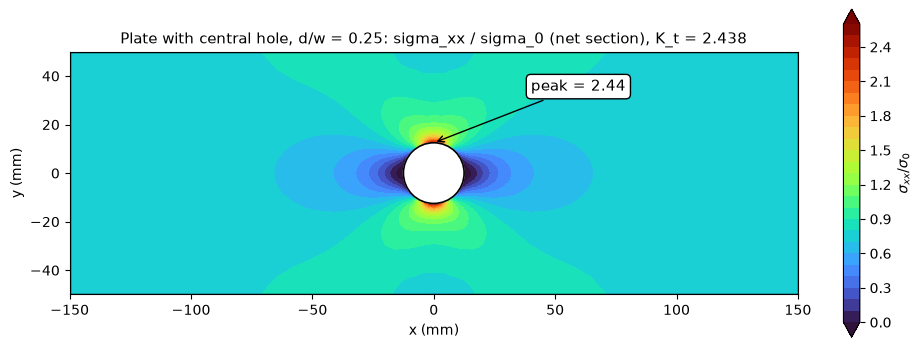

In [7]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

def quadrant_triangulation(coord, tri6, values, sx=1, sy=1, scale=1e3):
    ids = sorted({n for row in tri6 for n in row}); pos = {n: i for i, n in enumerate(ids)}
    x = np.array([coord[n][0] for n in ids]) * sx * scale; y = np.array([coord[n][1] for n in ids]) * sy * scale
    sub = []
    for n0, n1, n2, n3, n4, n5 in tri6:                       # corners 0-2, mid-sides 01, 12, 20
        sub += [(n0, n3, n5), (n3, n1, n4), (n5, n4, n2), (n3, n4, n5)]
    t = np.array([[pos[a], pos[b], pos[c]] for a, b, c in sub])
    return mtri.Triangulation(x, y, t), np.array([values[n] for n in ids])

R_mm, HW_mm, LH_mm = 1e3 * D / 2, 1e3 * W / 2, 1e3 * 1.5 * W
ratio = {n: st[n][0] / SIG_NOM for n in st}                    # sigma_xx / sigma_0 at every node
levels = np.linspace(0.0, 2.6, 27)
fig, ax = plt.subplots(figsize=(10, 4.4))
for sx, sy in [(1, 1), (-1, 1), (1, -1), (-1, -1)]:
    T, z = quadrant_triangulation(coord, tri, ratio, sx, sy)
    cs = ax.tricontourf(T, z, levels=levels, cmap="turbo", extend="both")
ax.add_patch(plt.Circle((0, 0), R_mm, color="white", zorder=3)); ax.add_patch(plt.Circle((0, 0), R_mm, fill=False, ec="k", lw=1.2, zorder=4))
ax.plot([-LH_mm, LH_mm, LH_mm, -LH_mm, -LH_mm], [-HW_mm, -HW_mm, HW_mm, HW_mm, -HW_mm], "k", lw=1)
ax.annotate(f"peak = {Kt_fem:.2f}", xy=(0, R_mm), xytext=(40, 34), arrowprops=dict(arrowstyle="->"), fontsize=11, zorder=5,
            bbox=dict(boxstyle="round", fc="white", ec="k"))
ax.set_aspect("equal"); ax.set_xlabel("x (mm)"); ax.set_ylabel("y (mm)")
ax.set_title(f"Plate with central hole, d/w = {D/W:.2f}: sigma_xx / sigma_0 (net section), K_t = {Kt_fem:.3f}", fontsize=11)
fig.colorbar(cs, ax=ax, shrink=0.8, label=r"$\sigma_{xx}/\sigma_0$"); fig.tight_layout(); plt.show()

## 2. The 2 m cantilever with 3D solids

**Problem.** A steel bar, $L = 2$ m, $50 \times 50$ mm section, is clamped at $x = 0$ and carries $P = 1$ kN at the tip in $-z$. The slender-beam result is the repository's shared benchmark,

$$\delta_{EB}=\frac{PL^3}{3EI} = 25.600 \text{ mm},\qquad I=\frac{bh^3}{12}$$

The comparison value adds Timoshenko's shear term,

$$\delta_T=\frac{PL^3}{3EI}+\frac{PL}{\kappa G A},\qquad G=\frac{E}{2(1+\nu)},\ \kappa=\tfrac{5}{6}\ \text{(rectangle)}$$

At $L/h = 40$ the shear term is only 0.05 %, but it is the right comparison, and §3 needs it. A solid model also has a clamped face that restrains the Poisson contraction, which makes the beam very slightly stiffer than either formula.

The mesh is quadratic tetrahedra (`C3D10`). gmsh numbers the last two mid-edge nodes of a 10-node tet differently from CalculiX, so those two columns are swapped on output. The result confirms the swap, since a wrong order gives a visibly wrong stiffness.

In [8]:
L, B, H, P = 2.0, 0.05, 0.05, 1000.0       # length, width, depth [m]; tip load [N]
I = B * H**3 / 12; A = B * H; G = E / (2 * (1 + NU))
d_EB = P * L**3 / (3 * E * I)
d_T = d_EB + P * L / ((5 / 6) * G * A)
print(f"Euler-Bernoulli {1e3 * d_EB:.4f} mm    Timoshenko {1e3 * d_T:.4f} mm")

def mesh_bar(h):
    gmsh.initialize(); gmsh.option.setNumber("General.Terminal", 0)
    try:
        gmsh.model.occ.addBox(0, 0, 0, L, B, H); gmsh.model.occ.synchronize()
        gmsh.option.setNumber("Mesh.MeshSizeMax", h); gmsh.option.setNumber("Mesh.MeshSizeMin", h * 0.5)
        gmsh.option.setNumber("Mesh.ElementOrder", 2); gmsh.option.setNumber("Mesh.HighOrderOptimize", 0)
        gmsh.model.mesh.generate(3)
        tags, xyz, _ = gmsh.model.mesh.getNodes()
        coord = dict(zip(tags.astype(int), xyz.reshape(-1, 3)))
        _, etags, enodes = gmsh.model.mesh.getElements(3)
        tet = np.array(enodes[0], dtype=int).reshape(-1, 10)
        tet[:, [8, 9]] = tet[:, [9, 8]]                    # gmsh -> CalculiX C3D10 node order
        etag = np.array(etags[0], dtype=int)
        eps = 1e-6
        fixed = gmsh.model.getEntitiesInBoundingBox(-eps, -eps, -eps, eps, B + eps, H + eps, 2)
        tipS = gmsh.model.getEntitiesInBoundingBox(L - eps, -eps, -eps, L + eps, B + eps, H + eps, 2)
        fixed_nodes = sorted({int(n) for _, t in fixed for n in gmsh.model.mesh.getNodes(2, t, includeBoundary=True)[0]})
        tip_nodes = sorted({int(n) for _, t in tipS for n in gmsh.model.mesh.getNodes(2, t, includeBoundary=True)[0]})
        tip_tris = np.vstack([np.array(gmsh.model.mesh.getElements(2, t)[2][0], dtype=int).reshape(-1, 6) for _, t in tipS])
        return coord, etag, tet, fixed_nodes, tip_nodes, tip_tris
    finally:
        gmsh.finalize()


def bar_inp(coord, etag, tet, fixed_nodes, tip_nodes, tip_tris):
    # consistent loads for uniform traction on 6-node triangles: corners 0, mid-sides area/3 each
    q = P / (B * H); force = {}
    for t in tip_tris:
        p = np.array([coord[n] for n in t[:3]])
        area = 0.5 * np.linalg.norm(np.cross(p[1] - p[0], p[2] - p[0]))
        for n in t[3:]:
            force[n] = force.get(n, 0.0) + q * area / 3
    assert abs(sum(force.values()) - P) < 1e-6 * P, "tip load does not sum to P"
    ids = sorted(coord)
    s = "*HEADING\ncantilever solid\n" + nodes_block(ids, np.array([coord[i] for i in ids]), 3)
    s += "*ELEMENT, TYPE=C3D10, ELSET=EALL\n" + "\n".join(
        f"{e}, " + ", ".join(str(n) for n in row) for e, row in zip(etag, tet)) + "\n"
    s += material() + "*SOLID SECTION, ELSET=EALL, MATERIAL=STEEL\n"
    s += nset_block("FIXED", fixed_nodes) + nset_block("TIP", tip_nodes)
    s += "*BOUNDARY\nFIXED, 1, 3\n"
    s += "*STEP\n*STATIC\n*CLOAD\n" + "\n".join(f"{n}, 3, {-f:.8g}" for n, f in sorted(force.items())) + "\n"
    s += "*NODE PRINT, NSET=TIP\nU\n*NODE FILE\nU, S\n*END STEP\n"
    return s


rows = []
for h in (0.025, 0.0167, 0.0125):
    m = mesh_bar(h)
    dat, _, frd = run_ccx("bar", bar_inp(*m))
    U = next(v for k, v in parse_dat(dat).items() if k[1] == "TIP")
    rows.append({"h (mm)": 1e3 * h, "nodes": len(m[0]), "tets": len(m[1]), "tip w (mm), mean over face": -1e3 * U[:, 3].mean()})
conv_bar = pd.DataFrame(rows)
conv_bar["vs Timoshenko (%)"] = 100 * (conv_bar["tip w (mm), mean over face"] / (1e3 * d_T) - 1)
display(conv_bar.round(4))
w_solid = conv_bar["tip w (mm), mean over face"].iloc[-1] / 1e3
check("2   Cantilever, C3D10 solids, tip w vs Timoshenko", w_solid, d_T, 0.005)

Euler-Bernoulli 25.6000 mm    Timoshenko 25.6125 mm


,h (mm),nodes,tets,"tip w (mm), mean over face",vs Timoshenko (%)
0,25.0,3540,1531,25.5535,-0.2301
1,16.7,13643,7126,25.5575,-0.2147
2,12.5,25943,14208,25.5615,-0.1992


OK   2   Cantilever, C3D10 solids, tip w vs Timoshenko: 0.0255615 vs 0.0256125  (-0.199 %, tolerance 0.5 %)


**Reading the result.** The solid is 0.2 % stiffer than Timoshenko's beam on the finest mesh, and the mesh is still moving by under 0.02 % per refinement. The clamped root accounts for much of the rest: beam theory lets the root section contract freely, while the solid model holds every node of it. A 0.5 % tolerance covers both.

### Bending stress on the deformed bar

Side view of the $y = 0$ face, with the displacement drawn at true scale and the depth axis stretched so the 50 mm section can be seen. The grey outline is the undeformed bar. The colour is the bending stress $\sigma_{xx}$ in MPa. At the root the beam formula gives $\sigma = Mc/I = PL(h/2)/I$, which the colour scale should reach. At the root the FE extremes are larger than $Mc/I$ (printed below the plot), because the fully clamped face restrains the Poisson contraction, and its corners are singular points. Away from the root the field follows the linear beam distribution: at mid-span the top fibre carries $Mc/I$ to the second decimal.

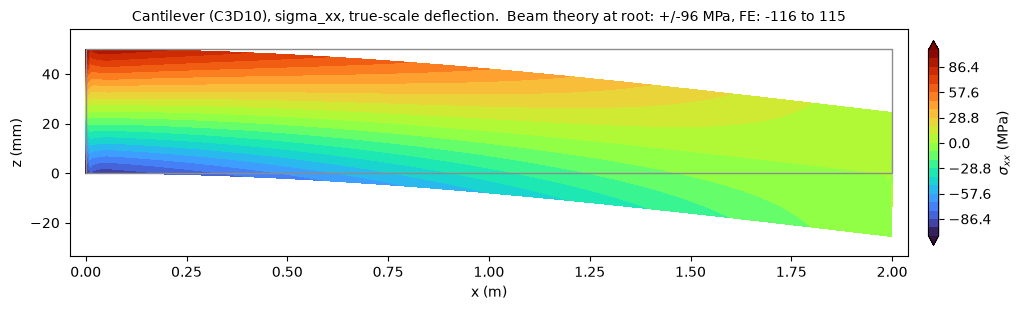

root extremes: FE -115.7 to 115.4 MPa vs Mc/I +/-96.0 MPa
top fibre at mid-span: FE 48.00 MPa vs Mc/I 48.00 MPa


In [9]:
coord_b, etag_b, tet_b, fixed_b, tip_b, tip_tris_b = m
Ub = parse_frd_blocks(frd, "DISP")[0]; Sb = parse_frd_blocks(frd, "STRESS")[0]
EDGE = {(0, 1): 4, (1, 2): 5, (0, 2): 6, (0, 3): 7, (1, 3): 8, (2, 3): 9}      # C3D10 mid-side positions
faces, sub = {(0, 1, 2), (0, 1, 3), (0, 2, 3), (1, 2, 3)}, []
for row in tet_b:
    for f in faces:
        if all(abs(coord_b[row[i]][1]) < 1e-9 for i in f):                 # face lies in the y = 0 plane
            a, b, c = f; ma, mb, mc = row[EDGE[(a, b)]], row[EDGE[(b, c)]], row[EDGE[(a, c)]]
            n0, n1, n2 = row[a], row[b], row[c]
            sub += [(n0, ma, mc), (ma, n1, mb), (mc, mb, n2), (ma, mb, mc)]
ids = sorted({n for t in sub for n in t}); pos = {n: i for i, n in enumerate(ids)}
xd = np.array([coord_b[n][0] + Ub[n][0] for n in ids]); zd = 1e3 * np.array([coord_b[n][2] + Ub[n][2] for n in ids])   # true-scale displacement
sig = np.array([Sb[n][0] for n in ids]) / 1e6                                # MPa
T = mtri.Triangulation(xd, zd, np.array([[pos[a], pos[b], pos[c]] for a, b, c in sub]))
sig_theory = P * L * (H / 2) / I / 1e6
fig, ax = plt.subplots(figsize=(11, 3.2))
cs = ax.tricontourf(T, sig, levels=np.linspace(-sig_theory * 1.1, sig_theory * 1.1, 23), cmap="turbo", extend="both")
ax.plot([0, L, L, 0, 0], [0, 0, 1e3 * H, 1e3 * H, 0], color="0.55", lw=1)
ax.set_xlim(-0.04, L + 0.04); ax.set_ylim(-1e3 * d_T - 8, 1e3 * H + 8)
ax.set_xlabel("x (m)"); ax.set_ylabel("z (mm)")
ax.set_title(f"Cantilever (C3D10), sigma_xx, true-scale deflection.  Beam theory at root: +/-{sig_theory:.0f} MPa, FE: {sig.min():.0f} to {sig.max():.0f}", fontsize=10)
fig.colorbar(cs, ax=ax, shrink=0.9, pad=0.02, label=r"$\sigma_{xx}$ (MPa)"); fig.tight_layout(); plt.show()

x_mid = np.array([coord_b[n][0] for n in ids]); top = np.array([abs(coord_b[n][2] - H) < 1e-9 for n in ids])
sel = top & (np.abs(x_mid - L / 2) < 0.03)
print(f"root extremes: FE {sig.min():.1f} to {sig.max():.1f} MPa vs Mc/I +/-{sig_theory:.1f} MPa")
print(f"top fibre at mid-span: FE {sig[sel].mean():.2f} MPa vs Mc/I {sig_theory / 2:.2f} MPa")

## 3. The same cantilever with beam elements

`B32` is a 3-node beam. CalculiX expands it internally into 3D 20-node bricks, so it is a second independent route to the same answer with tens of nodes instead of thousands. The section is `RECT`, $50 \times 50$ mm, with the beam's 1-direction along local $y$ and the normal $(0, 0, 1)$.

**Which closed form?** CalculiX beam elements include shear deformation, so the comparison value is Timoshenko's, not Euler-Bernoulli's. On the 2 m bar the two differ by only 0.05 %, too little to tell them apart. So check 3b uses a **short beam**, $L = 150$ mm ($L/h = 3$), where the shear term is about 9 % of the deflection: B32 should land on $\delta_T$ and well above $\delta_{EB}$.

In [10]:
def beam_inp(nel=10, length=L):
    nn = 2 * nel + 1
    xs = np.linspace(0, length, nn)
    s = "*HEADING\ncantilever beam\n*NODE\n" + "\n".join(f"{i+1}, {x:.10g}, 0, 0" for i, x in enumerate(xs)) + "\n"
    s += "*ELEMENT, TYPE=B32, ELSET=EALL\n" + "\n".join(f"{k+1}, {2*k+1}, {2*k+2}, {2*k+3}" for k in range(nel)) + "\n"
    s += material() + "*BEAM SECTION, ELSET=EALL, MATERIAL=STEEL, SECTION=RECT\n"
    s += f"{B:.10g}, {H:.10g}\n0., 0., 1.\n"
    s += f"*NSET, NSET=FIXED\n1\n*NSET, NSET=TIP\n{nn}\n"
    s += "*BOUNDARY\nFIXED, 1, 6\n"
    s += f"*STEP\n*STATIC\n*CLOAD\n{nn}, 3, {-P}\n*NODE PRINT, NSET=TIP\nU\n*END STEP\n"
    return s


def tip_w(nel, length=L):
    dat, _, _ = run_ccx("beam", beam_inp(nel, length))
    U = next(v for k, v in parse_dat(dat).items() if k[1] == "TIP")
    return -U[0, 3]


conv_beam = pd.DataFrame({"B32 elements": [10, 20, 40]})
conv_beam["tip w (mm)"] = [1e3 * tip_w(n) for n in conv_beam["B32 elements"]]
conv_beam["vs EB (%)"] = 100 * (conv_beam["tip w (mm)"] / (1e3 * d_EB) - 1)
conv_beam["vs Timoshenko (%)"] = 100 * (conv_beam["tip w (mm)"] / (1e3 * d_T) - 1)
display(conv_beam.round(5))
w_beam = conv_beam["tip w (mm)"].iloc[-1] / 1e3
w_rich = 2 * w_beam - conv_beam["tip w (mm)"].iloc[-2] / 1e3                # first-order Richardson from 20 and 40 elements
print(f"extrapolated from 20 and 40 elements: {1e3 * w_rich:.4f} mm ({100 * (w_rich / d_T - 1):+.3f} % from Timoshenko)")

L_SHORT = 0.150                                                   # short beam [m], L/h = 3
d_EB_s = P * L_SHORT**3 / (3 * E * I)
d_T_s = d_EB_s + P * L_SHORT / ((5 / 6) * G * A)
w_short = tip_w(40, L_SHORT)
print(f"short beam: B32 {1e3 * w_short:.6f} mm   Timoshenko {1e3 * d_T_s:.6f} mm   EB {1e3 * d_EB_s:.6f} mm   "
      f"(B32 is {100 * (w_short / d_EB_s - 1):+.2f} % from EB)")

check("3a  Cantilever, B32 beams, tip w vs Timoshenko", w_beam, d_T, 0.005)
check("3b  Short beam L/h = 3, B32 tip w vs Timoshenko", w_short, d_T_s, 0.005)

,B32 elements,tip w (mm),vs EB (%),vs Timoshenko (%)
0,10,25.27211,-1.28082,-1.32892
1,20,25.45550,-0.56445,-0.61290
2,40,25.53242,-0.26398,-0.31258


extrapolated from 20 and 40 elements: 25.6093 mm (-0.012 % from Timoshenko)


short beam: B32 0.011737 mm   Timoshenko 0.011736 mm   EB 0.010800 mm   (B32 is +8.67 % from EB)
OK   3a  Cantilever, B32 beams, tip w vs Timoshenko: 0.0255324 vs 0.0256125  (-0.313 %, tolerance 0.5 %)
OK   3b  Short beam L/h = 3, B32 tip w vs Timoshenko: 1.17369e-05 vs 1.1736e-05  (+0.007 %, tolerance 0.5 %)


**Reading the result.** The 2 m beam converges on Timoshenko from the stiff side, and only at about first order: the error roughly halves each time the element count doubles. Ten B32 elements are 1.3 % stiff on a straight cantilever, so a beam model in CalculiX needs an element study too. Extrapolating from 20 and 40 elements lands within about 0.01 % of $\delta_T$, and 40 elements are inside the 0.5 % tolerance. The short beam settles which closed form CalculiX follows: it lands on Timoshenko to about 0.01 %, and 8.7 % above Euler-Bernoulli, far outside the tolerance.

## 4. Linear buckling of the same bar as a fixed-free column

This is the check scikit-fem is not built for. CalculiX solves the eigenproblem $(K + \lambda K_\sigma)\phi=0$ for a reference load, and the lowest factor $\lambda_1$ is the critical load.

**Closed form.** Shigley Eq. (4-43), $P_{cr}=C\pi^2EI/l^2$, with the fixed-free end-condition constant $C = 1/4$ (Table 4-2, theoretical value). The column is the same 2 m bar, $50 \times 50$ mm, so $l/k = 139$. For $C = 1/4$ the Euler-Johnson transition $(l/k)_1 = \sqrt{2\pi^2 C E / S_y}$ is about 63 even for a low 250 MPa yield strength, so this is a genuine Euler column.

A 1 N compressive reference load at the tip makes $\lambda_1$ equal $P_{cr}$ in newtons.

In [11]:
C_END = 0.25
P_cr = C_END * math.pi**2 * E * I / L**2
print(f"Euler P_cr = {P_cr / 1e3:.3f} kN   (l/k = {L / math.sqrt(I / A):.1f})")

def column_inp(nel=10, nmodes=3):
    s = beam_inp(nel).split("*STEP")[0]
    nn = 2 * nel + 1
    s += f"*NSET, NSET=ALLN, GENERATE\n1, {nn}\n"     # every node, for the mode shape
    s += f"*STEP\n*BUCKLE\n{nmodes}\n*CLOAD\n{nn}, 1, -1.0\n*NODE PRINT, NSET=ALLN\nU\n*END STEP\n"
    return s

# the column must be restrained only at the root; the tip must be free to deflect in y and z
rows = []
for nel in (10, 20, 40):
    dat, console, _ = run_ccx("column", column_inp(nel))
    txt = dat + "\n" + console
    i = txt.find("B U C K L I N G")
    factors = [float(m_.group(2)) for m_ in re.finditer(r"^\s*(\d+)\s+([-+]?\d\.\d+E[-+]\d+)\s*$", txt[i:], re.M)]
    rows.append({"B32 elements": nel, "P_cr (kN)": factors[0] / 1e3, "vs Euler (%)": 100 * (factors[0] / P_cr - 1)})
display(pd.DataFrame(rows).round(4))
print("40 elements, first three buckling factors (kN):", [f"{f / 1e3:.3f}" for f in factors[:3]])
lam1 = factors[0]
check("4   Fixed-free column buckling vs Eq. (4-43)", lam1, P_cr, 0.005)

Euler P_cr = 64.255 kN   (l/k = 138.6)


,B32 elements,P_cr (kN),vs Euler (%)
0,10,64.8307,0.8955
1,20,64.4859,0.3589
2,40,64.3543,0.1542


40 elements, first three buckling factors (kN): ['64.354', '64.357', '577.095']
OK   4   Fixed-free column buckling vs Eq. (4-43): 64354.3 vs 64255.2  (+0.154 %, tolerance 0.5 %)


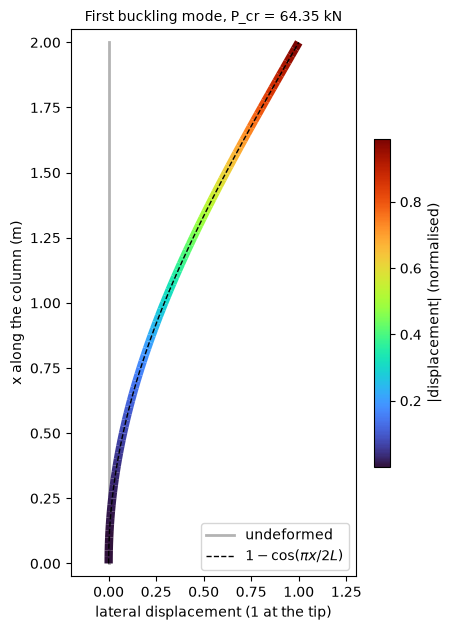

largest departure from the analytic shape: 0.0006 of the tip displacement


In [12]:
from matplotlib.collections import LineCollection
starts = [m_.start() for m_ in re.finditer(r"displacements .* for set ALLN", dat)]   # block 0 is the static pre-load, then one per mode
mode1 = next(iter(parse_dat(dat[starts[1]:starts[2]]).values()))
xs = np.linspace(0, L, len(mode1))
uy, uz = mode1[:, 2], mode1[:, 3]
ang = math.atan2(uz[-1], uy[-1])
lat = uy * math.cos(ang) + uz * math.sin(ang)                                  # bending direction the solver picked
lat = lat / lat[-1]                                                            # normalise: 1 at the tip
shape = 1 - np.cos(np.pi * xs / (2 * L))                                       # analytic fixed-free mode
pts = np.column_stack([lat, xs]).reshape(-1, 1, 2)
lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], axis=1), cmap="turbo", linewidths=6)
lc.set_array(0.5 * (np.abs(lat[:-1]) + np.abs(lat[1:])))
fig, ax = plt.subplots(figsize=(4.6, 6.4))
ax.plot(np.zeros_like(xs), xs, color="0.7", lw=2, label="undeformed")
ax.add_collection(lc); ax.plot(shape, xs, "k--", lw=1, label=r"$1-\cos(\pi x/2L)$")
ax.set_xlim(-0.2, 1.3); ax.set_ylim(-0.05, L + 0.05)
ax.set_ylabel("x along the column (m)"); ax.set_xlabel("lateral displacement (1 at the tip)")
ax.set_title(f"First buckling mode, P_cr = {lam1 / 1e3:,.2f} kN", fontsize=10)
ax.legend(loc="lower right"); fig.colorbar(lc, ax=ax, shrink=0.6, label="|displacement| (normalised)"); fig.tight_layout(); plt.show()
print(f"largest departure from the analytic shape: {np.abs(lat - shape).max():.4f} of the tip displacement")

**Reading the result.** With a unit load, the first factor is the critical load directly. Like the deflection in §3, it converges from the stiff side at about first order: 10 elements are 0.9 % high and 40 are 0.15 % high, so the check uses 40 and a 0.5 % tolerance. Higher modes of a symmetric section come in pairs (bending about each principal axis), which is why modes 1 and 2 are equal for this square bar. The mode shape matches the fixed-free cosine to within 0.1 % of the tip displacement.

## CalculiX notes

Traps found while building this notebook, where they bite:

- **Stresses go only to the `.frd`.** `*NODE PRINT` takes `U` and `RF`. With `S` it warns "label not applicable" and leaves the `.dat` empty, so use `*NODE FILE` with `S` and parse the fixed-width `.frd`.
- **gmsh's 10-node tet differs from C3D10** in the last two mid-edge nodes. Swap columns 8 and 9 (§2).
- **B32 includes shear deformation,** so compare beams with Timoshenko, not Euler-Bernoulli. It shows only on short beams (§3, check 3b).
- **B32 is too stiff with few elements and converges only at about first order,** even on a straight cantilever. Ten elements give a tip deflection 1.3 % low and a buckling load 0.9 % high (§3, §4). Run an element study; doubling the count roughly halves the error.
- **Plane-stress elements are 3D slabs.** `CPS6` is expanded into wedges of the section thickness. A thickness comparable with the hole radius gives a 3D, thickness-dependent $K_t$ several percent above the plane-stress value (§1.3). Keep the section thin when you want the plane-stress answer.
- **Run it in a temporary folder.** `ccx` writes several scratch files beside the `.inp`. `run_ccx` uses a temp folder, so none of them land in your project or a synced folder.

## Results

In [13]:
tbl = pd.DataFrame(CHECKS)
print(tbl.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
failed = tbl.loc[tbl.result != "OK", "check"].tolist()
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"\nall {len(tbl)} checks passed")

                                            check    CalculiX  closed form   error %  tolerance % result
                     1a  Wide plate, Kt vs Kirsch     3.00424            3  0.141333          0.5     OK
          1b  Plate d/w = 0.25, Kt vs Howland fit     2.43764      2.42234  0.631568            1     OK
   1c  Plate d/w = 0.25, Kt vs Shigley chart 2.45     2.43764         2.45 -0.504388            2     OK
2   Cantilever, C3D10 solids, tip w vs Timoshenko   0.0255615    0.0256125 -0.199177          0.5     OK
   3a  Cantilever, B32 beams, tip w vs Timoshenko   0.0255324    0.0256125 -0.312582          0.5     OK
  3b  Short beam L/h = 3, B32 tip w vs Timoshenko 1.17369e-05   1.1736e-05 0.0074983          0.5     OK
     4   Fixed-free column buckling vs Eq. (4-43)     64354.3      64255.2  0.154202          0.5     OK

all 7 checks passed
